## **Introduction**
- **MLP Project**
- **Name -** Ritik Ranjan
- **Roll no. -** [roll no. removed]
- **Email Id -** [email removed]

## **IMPORTING LIBRARIES**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

### **IMPORTING DATASETS**

In [3]:
df_train = pd.read_csv("/kaggle/input/sentiment-prediction-on-movie-reviews/train.csv")
df_test = pd.read_csv("/kaggle/input/sentiment-prediction-on-movie-reviews/test.csv")
df_sample = pd.read_csv("/kaggle/input/sentiment-prediction-on-movie-reviews/sample.csv")
df_movies = pd.read_csv("/kaggle/input/sentiment-prediction-on-movie-reviews/movies.csv")

### **EDA (Exploratory Data Analysis)**

**checking for duplicates**

In [4]:
print("Duplicates in movies_df:", df_movies.duplicated().sum())
print("Duplicates in train_df:", df_train.duplicated().sum())
print("Duplicates in test_df:", df_test.duplicated().sum())

Duplicates in movies_df: 1571
Duplicates in train_df: 1118
Duplicates in test_df: 97


**Dropping duplicates from movies**

In [5]:
df_movies = df_movies.drop_duplicates(subset=['movieid'])

In [6]:
print("Duplicates in df_movies:", df_movies.duplicated().sum())

Duplicates in df_movies: 0


In [7]:
df_movies.shape

(126404, 14)

In [8]:
df_movies.head()

,movieid,title,audienceScore,rating,ratingContents,releaseDateTheaters,releaseDateStreaming,runtimeMinutes,genre,originalLanguage,director,boxOffice,distributor,soundType
0,han_solo_heroic_myth_wonder_woman,Han Solo Heroic Myth Wonder Woman,50.0,NaN,NaN,NaN,2018-08-25,75.0,"Comedy, Horror, Sci-fi",English,Claude Nicolet,NaN,NaN,NaN
1,voyage_tyler_durden_han_solo_stardust,Voyage Tyler Durden Han Solo Stardust,NaN,NaN,NaN,NaN,2020-02-11,114.0,Drama,English,Nathan Haack,NaN,NaN,NaN
2,norman_bates_ferris_bueller_hermione_granger_v...,Norman Bates Ferris Bueller Hermione Granger V...,43.0,NaN,NaN,NaN,NaN,120.0,Drama,Korean,Theresa Smith,NaN,NaN,NaN
3,elegant_hermione_granger,Elegant Hermione Granger,60.0,NaN,NaN,NaN,2020-10-23,90.0,"Action, Mystery & thriller",English,Donald Lewis,NaN,NaN,NaN
4,adventure_rocky_balboa,Adventure Rocky Balboa,70.0,NaN,NaN,NaN,2017-03-27,80.0,"Fantasy, Adventure, Animation",English,Howard Simms,NaN,NaN,NaN


In [9]:
df_movies.shape

(126404, 14)

### **Merging Movies.csv with Train and Test**

In [10]:
train_data = pd.merge(df_train, df_movies,how='left', on="movieid")
test_data = pd.merge(df_test, df_movies,how='left', on="movieid")

In [11]:
train_data.shape, test_data.shape

((162758, 18), (55315, 17))

In [12]:
train_data.columns

Index(['movieid', 'reviewerName', 'isFrequentReviewer', 'reviewText',
       'sentiment', 'title', 'audienceScore', 'rating', 'ratingContents',
       'releaseDateTheaters', 'releaseDateStreaming', 'runtimeMinutes',
       'genre', 'originalLanguage', 'director', 'boxOffice', 'distributor',
       'soundType'],
      dtype='object')

/tmp/ipykernel_20/3032478212.py:5: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = train_data.corr()


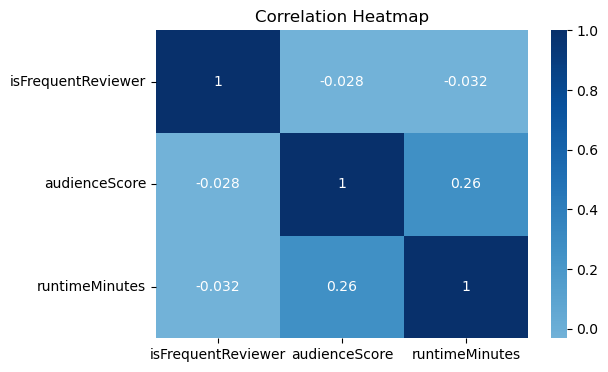

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = train_data.corr()
plt.figure(figsize=(6, 4))
sns.heatmap(correlation_matrix, annot=True, cmap="Blues", center=0)
plt.title("Correlation Heatmap")
plt.show()


## **Splitting the data**

In [14]:
from sklearn.model_selection import train_test_split
x_train = train_data[['reviewText', 'audienceScore', 'runtimeMinutes']]
y_train = train_data['sentiment']
test = test_data[['reviewText', 'audienceScore', 'runtimeMinutes']]
x_train['reviewText'].fillna('', inplace=True)
test['reviewText'].fillna('', inplace=True)

X_train_exp, X_test_exp, y_train, y_test = train_test_split(x_train, y_train, test_size=0.2, random_state=42)

X_train_exp.shape, X_test_exp.shape, test.shape, y_train.shape, y_test.shape

/tmp/ipykernel_20/3188596417.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x_train['reviewText'].fillna('', inplace=True)
/tmp/ipykernel_20/3188596417.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test['reviewText'].fillna('', inplace=True)


((130206, 3), (32552, 3), (55315, 3), (130206,), (32552,))

In [15]:
x_train.isna().sum()

reviewText            0
audienceScore     13248
runtimeMinutes     3376
dtype: int64

In [16]:
train_data.shape

(162758, 18)

In [17]:
test_data.shape

(55315, 17)

In [18]:
train_data.describe()

,audienceScore,runtimeMinutes
count,149510.000000,159382.000000
mean,65.214541,106.911828
std,19.937695,22.138131
min,0.000000,4.000000
25%,51.000000,93.000000
50%,68.000000,104.000000
75%,82.000000,118.000000
max,100.000000,561.000000


From the above description we can get some insights about the various data like the total number of counts present in the columns audienceScore and runtimeMinutes. We can also have a look what the standard deviation and mean looks like as well as various percentiles.

**sentiment count**

In [19]:
train_data['sentiment'].value_counts()

POSITIVE    108761
NEGATIVE     53997
Name: sentiment, dtype: int64

from the above value counts we can see the total number of counts of Positive and Negative sentiments present in the data.

## Data Visualization

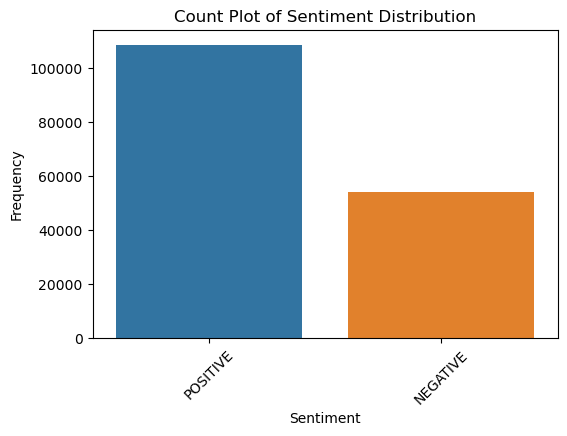

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.countplot(x='sentiment', data=train_data)
plt.xlabel('Sentiment')
plt.ylabel('Frequency')
plt.title('Count Plot of Sentiment Distribution')
plt.xticks(rotation=45)
plt.show()


From the above graph we can get an overview of how the sentiment distribution looks like

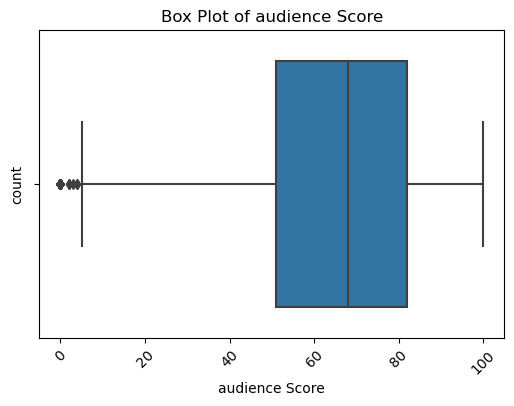

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(6, 4))
sns.boxplot(x='audienceScore', data=train_data)
plt.xlabel('audience Score')
plt.ylabel('count')
plt.title('Box Plot of audience Score')
plt.xticks(rotation=45)
plt.show()


The Box plot plotted above shows that there are some outliers present in the data and the mean is somewhere around 65 , the Q1 is around 55 and Q3 stands somewhere near 80

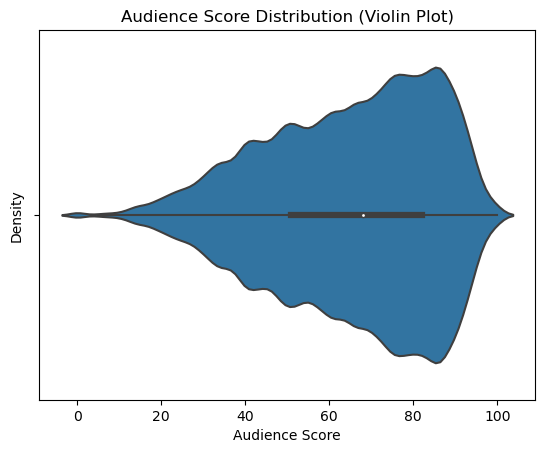

In [22]:
data = train_data
sns.violinplot(x='audienceScore', data=data)
plt.title('Audience Score Distribution (Violin Plot)')
plt.xlabel('Audience Score')
plt.ylabel('Density')
plt.show()

The above Violin plot shows the density structure of audienceScore in the data.

In [23]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 162758 entries, 0 to 162757
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   movieid               162758 non-null  object 
 1   reviewerName          162758 non-null  object 
 2   isFrequentReviewer    162758 non-null  bool   
 3   reviewText            156311 non-null  object 
 4   sentiment             162758 non-null  object 
 5   title                 162758 non-null  object 
 6   audienceScore         149510 non-null  float64
 7   rating                99034 non-null   object 
 8   ratingContents        99034 non-null   object 
 9   releaseDateTheaters   126924 non-null  object 
 10  releaseDateStreaming  146573 non-null  object 
 11  runtimeMinutes        159382 non-null  float64
 12  genre                 160320 non-null  object 
 13  originalLanguage      159468 non-null  object 
 14  director              162758 non-null  object 
 15  

In [24]:
df_train.head()

,movieid,reviewerName,isFrequentReviewer,reviewText,sentiment
0,marvelous_pirate,Benjamin Henry,False,Henry Selick’s first movie since 2009’s Corali...,POSITIVE
1,tony_montana_frodo_baggins_v_rocky_balboa,Felicia Lopez,False,With a cast that reads like the Vogue Oscar pa...,NEGATIVE
2,darth_vader_katniss_everdeen_sorcerer_donnie_d...,Mr. Charles Burgess,True,Creed II does not give us anything but another...,POSITIVE
3,lara_croft_glimmer,Ryan Barrett,False,"I know what you're thinking, but this is no Li...",POSITIVE
4,jason_bourne_surreal_the_terminator_indiana_jones,Alexander Glover,False,Director Fernando Meirelles tells the story wi...,POSITIVE


In [25]:
print(df_train.shape, df_test.shape)

(162758, 5) (55315, 4)


### Data preprocessing

In [26]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162758 entries, 0 to 162757
Data columns (total 5 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   movieid             162758 non-null  object
 1   reviewerName        162758 non-null  object
 2   isFrequentReviewer  162758 non-null  bool  
 3   reviewText          156311 non-null  object
 4   sentiment           162758 non-null  object
dtypes: bool(1), object(4)
memory usage: 5.1+ MB


In [27]:
df_train.isnull().sum()

movieid                  0
reviewerName             0
isFrequentReviewer       0
reviewText            6447
sentiment                0
dtype: int64

In [28]:
df_train.isnull().sum()

movieid                  0
reviewerName             0
isFrequentReviewer       0
reviewText            6447
sentiment                0
dtype: int64

In [29]:
df_test.isnull().sum()

movieid            0
reviewerName       0
isTopCritic        0
reviewText      2510
dtype: int64

In [30]:
df_test

,movieid,reviewerName,isTopCritic,reviewText
0,legend_marty_mcfly_oracle,John Kim,False,Green slowly cranks up the dread with style an...
1,terminator_katniss_everdeen_glimmer,Brian Chaney,False,Philip Noyce's direction is elegant and unforc...
2,james_bond_labyrinth_gollum,Danielle Parker,False,It wouldn't do to say what path Maria ultimate...
3,v_quest_han_solo_wondrous,Brittany Lane,False,Pig is not exactly the arthouse John Wick that...
4,enigma_hulk_surreal_starlight,Justin Willis,False,An imaginative no-budget musical of sorts abou...
...,...,...,...,...
55310,celestial_radiant,Jose Mccormick,False,Ron Howard delivers an unconventional romantic...
55311,vivid_james_t._kirk,Thomas Osborne,False,As an oddball art film that openly invites you...
55312,scarlett_o'hara_neo_scarlett_o'hara_infinite,Julie Kirby,False,Nicholson wears his devilish grin from his fir...
55313,terminator_epic_rocky_balboa_mystic,Tina Sutton,True,It's hard not be entertained by two dozen of C...


In [31]:
df_test.isnull().sum()

movieid            0
reviewerName       0
isTopCritic        0
reviewText      2510
dtype: int64

In [32]:
print(df_train.shape, df_test.shape)

(162758, 5) (55315, 4)


### One hot encoding

In [33]:
# from sklearn.preprocessing import OneHotEncoder

# categorical_columns = ['isFrequentReviewer', 'sentiment']  # List of categorical columns
# data_categorical = df_train['categorical_columns']
# encoder = OneHotEncoder(sparse=False)
# encoded_data = encoder.fit_transform(data_categorical)
# encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names(categorical_columns))
# df_train_encoded = pd.concat([data.drop(categorical_columns, axis=1), encoded_df], axis=1)

# df_train_encoded

In [34]:
# categorical_columns = ['isFrequentReviewer', 'sentiment']
# data_categorical = df_train['categorical_columns']

In [35]:
# X = df_train["reviewText"]
# X.head(1)

### Ordinal Encoding

In [36]:
# from sklearn.preprocessing import OrdinalEncoder

# oe = OrdinalEncoder()
# df_train['sentiment_code'] = oe.fit_transform(df_train[['sentiment']])
# df_train.head(1)


In [37]:
# df_train.head(1)

In [38]:
# y =  df_train['sentiment']
# y

In [39]:
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Models

### Dummy Classifier

In [40]:
# dummy_clf = DummyClassifier(strategy="most_frequent") 
# dummy_clf.fit(X_train, y_train)

# y_pred = dummy_clf.predict(X_test)

# accuracy = accuracy_score(y_test, y_pred)
# print("Accuracy:", accuracy)

**Accuracy of Dummy Classifier =** 0.6714180388301794

### **KNN CLASSIFIER**

In [41]:
# from sklearn.neighbors import KNeighborsClassifier
# np.random.seed(42)

# knn = GridSearchCV(KNeighborsClassifier(algorithm='auto'),\
#                   {'n_neighbors':[2,4,5],\
#                   'weights':['uniform', 'distance'],\
#                   'metric':['euclidean', 'manhattan']},cv=5)
# knn.fit(X_train, y_train)
# knn.score(X_train, y_train)

In [42]:
# knn.best_params_
# {'metric': 'manhattan', 'n_neighbors':5, 'weights': 'distance'}
# 0.9848086877716848

In [43]:
# tuned_knn = KNeighborsClassifier(n_neighbors=5)
# tuned_knn.fit(X_train, y_train)

In [44]:
# X_trainRev=df_train['reviewText']
# y_trainSen=df_train['sentiment']
# X_testRev=df_test['reviewText']
# y=y_trainSen.map({'NEGATIVE':0, 'POSITVE':1})


**Accuracy of KNN after the final submission :** 0.6514180388301794

## **Logistic Regression**

### **Pipeline and feature Union**

In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer

#Scalers and vectorisers
vt = TfidfVectorizer(ngram_range=(1,2))
ss = StandardScaler(with_mean=False, with_std=True)
rr = RobustScaler()

#Imputers
si2= SimpleImputer()
si3 =SimpleImputer()

audience = Pipeline([('num1', si2), ('au', ss)])
runtime = Pipeline([('num2', si3), ('run', rr)])

pre1 = ColumnTransformer([('aud', audience, ['audienceScore']),
                           ('runt', runtime, ['runtimeMinutes'])],
                         verbose_feature_names_out= False)

pre2 = ColumnTransformer([('rev', vt, 'reviewText')],
                         verbose_feature_names_out= False)

preprocessor = FeatureUnion([('pre1', pre1), ('pre2', pre2)])

X_train_enc = preprocessor.fit_transform(X_train_exp)
X_test_enc =preprocessor.transform(X_test_exp)
test_enc = preprocessor.transform(test)

### **Logistic model**

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder


# Create a logistic regression model
log_model = LogisticRegression(C=15 , max_iter=1500, solver='saga', penalty='l2')
svc_model = LinearSVC(penalty='l2', loss='squared_hinge', tol=0.01, C=0.5, fit_intercept=True,max_iter=1500,dual =True)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
# Training the logistic regression model on the training data
svc_model.fit(X_train_enc, y_train_enc)
# Making predictions on the testing data
y_pred = svc_model.predict(X_test_enc)
# Calculating the accuracy of the logistic regression model
accuracy = accuracy_score(y_test_enc, y_pred)
print("Logistic Regression Accuracy:", accuracy)
# Calculating the F1 score of the logistic regression model
f1 = f1_score(y_test_enc, y_pred, average='micro')
print("Logistic Regression F1 Score:", f1)

# y_pred_svc = le.inverse_transform(y_pred)
# y_pred_svc[:5]

Logistic Regression Accuracy: 0.8269230769230769
Logistic Regression F1 Score: 0.8269230769230769


**Logistic Regression Accuracy:** 0.8277525190464488

**Logistic Regression F1 Score:** 0.8277525190464488

**Logistic Regression Accuracy:** 0.8269230769230769

**Logistic Regression F1 Score:** 0.8269230769230769

**Classification Report after using logistic regression with three features namely reviewText , audienceScore & runtimeMinutes**

In [47]:
from sklearn.metrics import classification_report
class_report = classification_report(y_test_enc, y_pred, target_names=le.classes_, output_dict=False)
print("Classification Report:")
print(class_report)


Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       0.77      0.67      0.72     10696
    POSITIVE       0.85      0.90      0.88     21856

    accuracy                           0.83     32552
   macro avg       0.81      0.79      0.80     32552
weighted avg       0.82      0.83      0.82     32552



The classification report provides detailed metrics for each class. The report include metrics such as precision, recall, F1-score, and support for each class. 

**Confusion Matrix**

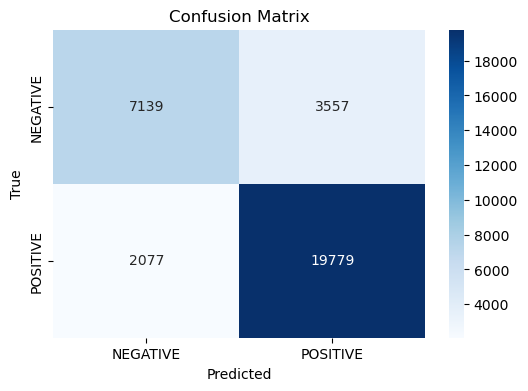

In [48]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
conf_matrix = confusion_matrix(y_test_enc, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


The confusion matrix provides a more granular view of the model's performance across all classes. It shows the actual and predicted counts for each class, which allows us to see where the model is making correct or incorrect predictions. 

**AUC curve of Linear SVC**

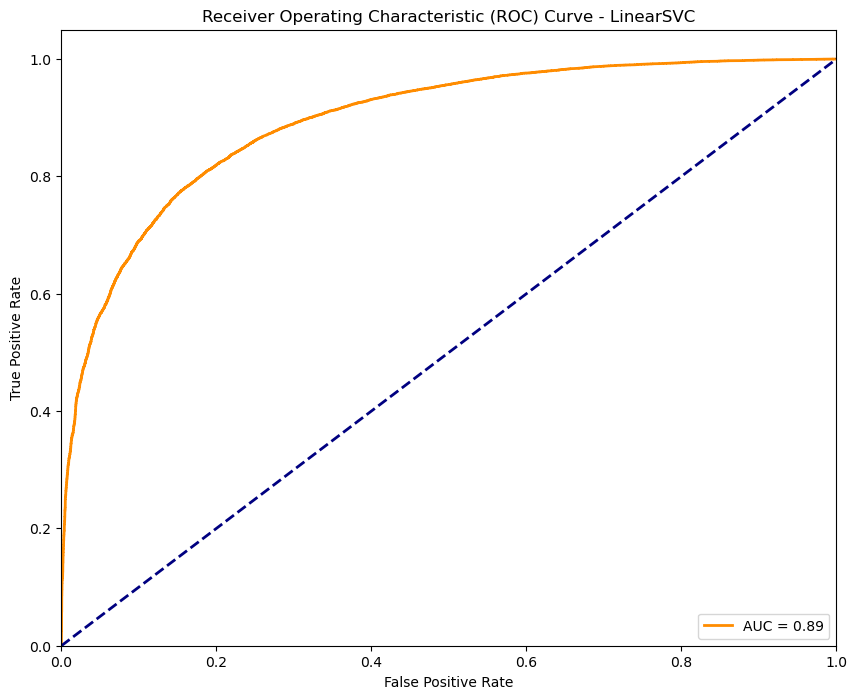

LinearSVC AUC: 0.8939557057563698


In [49]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

decision_scores_svc = svc_model.decision_function(X_test_enc)
y_pred_prob_svc = (decision_scores_svc - decision_scores_svc.min()) / (decision_scores_svc.max() - decision_scores_svc.min())
fpr_svc, tpr_svc, _ = roc_curve(y_test_enc, y_pred_prob_svc)
roc_auc_svc = auc(fpr_svc, tpr_svc)
plt.figure(figsize=(10, 8))
plt.plot(fpr_svc, tpr_svc, color='darkorange', lw=2, label=f'AUC = {roc_auc_svc:.2f}')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - LinearSVC')
plt.legend(loc='lower right')
plt.show()

print("LinearSVC AUC:", roc_auc_svc)


The AUC-ROC curve provides insights into the model's ability to discriminate between positive and negative instances. The curve plots the True Positive Rate (sensitivity) against the False Positive Rate (1-specificity) at various threshold levels. The area under the curve (AUC) quantifies the overall performance of the model.

In [50]:
from sklearn.linear_model import SGDClassifier

sgd_model = SGDClassifier(loss='hinge', alpha=0.0001, max_iter=1000, random_state=42)
sgd_model.fit(X_train_enc, y_train_enc)
y_pred_sgd = sgd_model.predict(X_test_enc)

accuracy_sgd = accuracy_score(y_test_enc, y_pred_sgd)
print("SGD Classifier Accuracy:", accuracy_sgd)

f1_sgd = f1_score(y_test_enc, y_pred_sgd, average='micro')
print("SGD Classifier F1 Score:", f1_sgd)


SGD Classifier Accuracy: 0.777248709756697
SGD Classifier F1 Score: 0.7772487097566969


**Logistic Regression and linear SVC with only one feature of reviewText**

In [51]:
# from sklearn.model_selection import train_test_split
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.linear_model import LogisticRegression
# from sklearn.svm import LinearSVC
# from sklearn.metrics import accuracy_score, f1_score
# from sklearn.preprocessing import LabelEncoder

# # Dropping rows with missing values
# df_train = df_train.fillna('')
# df_test = df_test.fillna('')

# # Splitting the data into training and testing sets
# X = train_data["reviewText"]
# y = train_data['sentiment']
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# # Creating a TfidfVectorizer to convert text into numerical features
# vectorizer = TfidfVectorizer(ngram_range=(1,2),max_df=0.5,sublinear_tf=False)

# # Fitting and transforming the training data
# X_train = vectorizer.fit_transform(X_train)

# # Transforming the testing data
# X_test = vectorizer.transform(X_test)
# test_data = test_data.fillna('')
# t_data = vectorizer.transform(test_data['reviewText'])

# # Creating a logistic regression model
# logistic_model = LogisticRegression(C=25 , max_iter=1500, solver='saga', penalty='l2')

# # Creating a LinearSVC model
# svc_model = LinearSVC(C=0.5, tol=0.001)

# le = LabelEncoder()
# y_train_enc = le.fit_transform(y_train)
# y_test_enc = le.fit_transform(y_test)

# # Training the logistic regression model on the training data
# logistic_model.fit(X_train, y_train_enc)

# # Making predictions on the testing data
# y_pred = logistic_model.predict(X_test)

# # Calculating the accuracy of the logistic regression model
# accuracy = accuracy_score(y_test_enc, y_pred)
# print("Logistic Regression Accuracy:", accuracy)

# # Calculating the F1 score of the logistic regression model
# f1 = f1_score(y_test_enc, y_pred, average='micro')
# print("Logistic Regression F1 Score:", f1)

# # Inverse transforming the predictions to get the original labels
# y_pred = le.inverse_transform(y_pred)

# # Training the LinearSVC model on the training data
# svc_model.fit(X_train, y_train_enc)

# # Making predictions on the testing data using LinearSVC
# y_pred_svc = svc_model.predict(X_test)

# # Calculating the accuracy of the LinearSVC model
# accuracy_svc = accuracy_score(y_test_enc, y_pred_svc)
# print("Linear SVC Accuracy:", accuracy_svc)

# # Calculating the F1 score of the LinearSVC model
# f1_svc = f1_score(y_test_enc, y_pred_svc, average='micro')
# print("Linear SVC F1 Score:", f1_svc)

# # Inverse transforming the predictions to get the original labels
# y_pred_svc = le.inverse_transform(y_pred_svc)


The Accuracy and F1 score after using one feature reviewText and some hyper para meter Tuning of Logistic Regression and Linear SVC model

**Logistic Regression Accuracy:** 0.8289351629722036

**Logistic Regression F1 Score:** 0.8289351629722035

**Linear SVC Accuracy:** 0.8303105907942296

**Linear SVC F1 Score:** 0.8303105907942296

Submission file of LogReg model with reviewText feature

In [52]:
# y_pred_test = svc_model.predict(t_data)
# y_pred_test = le.inverse_transform(y_pred_test)
# y_pred_test

Submission file of LogReg model with audienceScore, runtimeMinutes & reviewText as features

In [53]:
y_pred_test = svc_model.predict(test_enc)
y_pred_test = le.inverse_transform(y_pred_test)
y_pred_test[:5]

array(['POSITIVE', 'POSITIVE', 'POSITIVE', 'POSITIVE', 'POSITIVE'],
      dtype=object)

In [54]:
# submission = pd.DataFrame(y_pred_test, columns=['sentiment'])
# submission.index.name ="id"
# submission.to_csv('submission.csv', index=True)
# print('Successful')

In [55]:
submission = pd.DataFrame(y_pred_test, columns=['sentiment'])
submission.index.name ="id"
submission.to_csv('submission.csv', index=True)
print('Successful')

Successful


### **Naive Bayes** With only reviewText

In [56]:
# from sklearn.naive_bayes import MultinomialNB
# from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


# # Create and train the Naive Bayes classifier
# nb_classifier = MultinomialNB()
# nb_classifier.fit(X_train, y_train)

# # Make predictions on the test data
# y_pred = nb_classifier.predict(X_test)

# # Evaluate the performance of the classifier
# accuracy = accuracy_score(y_test, y_pred)
# precision = precision_score(y_test, y_pred, average='macro')
# recall = recall_score(y_test, y_pred, average='macro')
# f1 = f1_score(y_test, y_pred, average='micro')

# print("Accuracy:", accuracy)
# print("Precision:", precision)
# print("Recall:", recall)
# print("F1 Score:", f1)

**Accuracy :** 0.6935994626235487

**Precision :** 0.8284254590666305

**Recall :** 0.5285213087367814

**F1 Score :** 0.6935994626235487

In [57]:
# from sklearn.svm import SVC
# from sklearn.model_selection import GridSearchCV
# np.random.seed(42)
# GS=GridSearchCV(SVC(), {'kernel':['linear', 'rbf'],\
#                         'C':[0.1, 1, 30]},cv=10)
# GS.fit(X_train, y_train)


In [58]:
# GS.best_params

### Cross Validation

In [59]:
# from sklearn.model_selection import cross_val_score
# from sklearn.model_selection import KFold
# from sklearn.svm import SVC

# # Instantiate the model
# svc = SVC()

# #setting up the cross validation
# kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# # Perform cross-validation
# scores = cross_val_score(svc, X, y, cv=kfold)

# # Print the cross-validation scores
# print("Cross-Validation Scores:", scores)

# # Calculate and print the mean accuracy and standard deviation
# print("Mean Accuracy:", scores.mean())
# print("Standard Deviation:", scores.std())

In [60]:
# test_labels = logistic_model.predict(df_test_review)
# df_test['sentiment'] = test_labels
# col1 = df_sample['id']
# col2 = df_test['sentiment']
# df = np.column_stack((col1, col2))
# pd.DataFrame(df, columns=['id', 'sentiment']).to_csv('submission.csv', index=False)
# print('Successful')


#### Count plot after applying Linear SVC model

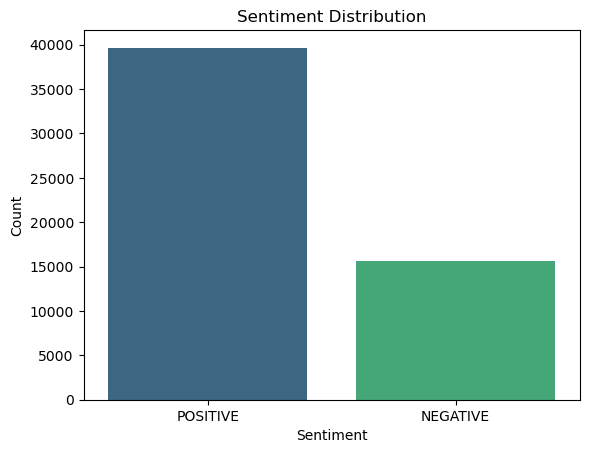

In [61]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

data = pd.Series(y_pred_test, name='sentiment')
sns.countplot(x=data, palette='viridis')  
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()


In [62]:
num_rows = df_test.shape[0]
print("Number of rows in 'test.csv':", num_rows)

Number of rows in 'test.csv': 55315


In [63]:
pd.read_csv("submission.csv")


,id,sentiment
0,0,POSITIVE
1,1,POSITIVE
2,2,POSITIVE
3,3,POSITIVE
4,4,POSITIVE
...,...,...
55310,55310,POSITIVE
55311,55311,NEGATIVE
55312,55312,NEGATIVE
55313,55313,POSITIVE


# Summary

**Models & F1_score on training data**

**Features:** reviewText

**1. Dummy classifier -** 0.67141 (strategy="most_frequent")

**2. KNN -** 0.65141 ('metric': 'manhattan', 'n_neighbors':5, 'weights': 'distance')

**3. Logistic Regression -** 0.82893 (C=25 , max_iter=1500, solver='saga', penalty='l2')

**4. Linear SVC -** 0.83031 (C=0.5, tol=0.001)

**5. Naive bayes -** 0.69359 MultinomialNB()

**Features:** reviewText , audienceScore , runtimeMinutes

**1. Logistic Regression -** 0.82775 (C=15 , max_iter=1500, solver='saga', penalty='l2')

**2. Linear SVC -** 0.82692 (penalty='l2', loss='squared_hinge', tol=0.01, C=0.5, fit_intercept=True,max_iter=1500,dual =True)

**3. SGDClassifier -** 0.77724 (loss='hinge', alpha=0.0001, max_iter=1000, random_state=42)


# 